# Decoding Left- and Right-Hand Motor Imagery from EEG Signals

**Author:** Jamiu Hassan | B.Sc. Human Anatomy, Bayero University Kano

An exploratory computational neuroscience project connecting anatomical knowledge with EEG analysis and machine learning. This is an independent learning project prepared for a Neurasmus application, not an official programme project.

**Question:** Can six central-electrode mu/beta power features distinguish imagined left- and right-hand movement across recordings from the same participant?

**Design:** PhysioNet EEG Motor Movement/Imagery Dataset, participant S001; R04 for model development and training, R08 and R12 for separate-run testing. Each run has 64 channels at 160 Hz and lasts 125 seconds. These are repeated runs from one participant, not independent participants.

**Status:** The analysis completed successfully in Kaggle. The cleaned workflow was verified against Version 2 on 12 October 2026, including 19/30 correct separate-run predictions. This presentation copy retains real saved outputs from matching code cells in the earlier successful Kaggle export; their execution numbers are preserved. Version 2 independently reproduced the reported results. Documentation has been updated without changing analysis code.

## How to run

Import this notebook into Kaggle, enable Internet access for the installation and PhysioNet downloads, and run cells from top to bottom in a fresh session. Paths target `/kaggle/working`. The first cell prints package versions. Save the completed notebook with outputs. This copy removes recovery cells, earlier exploratory settings and a duplicate final evaluation; it does not retune the model.


## 1. Environment

Import the analysis libraries. Package versions are printed for reproducibility; this notebook does not pin an unverified environment.

In [1]:
import sys

!{sys.executable} -m pip install -q mne

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
import sklearn

print("Python:", sys.version.split()[0])
print("MNE:", mne.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
import scipy
print("SciPy:", scipy.__version__)
print("scikit-learn:", sklearn.__version__)
print("Setup complete!")

Python: 3.13.15
MNE: 1.13.2
NumPy: 2.1.3
Pandas: 2.3.3
SciPy: 1.16.3
scikit-learn: 1.6.1
Setup complete!


## 2. Download and inspect R04

R04 is left/right motor imagery: T0 = rest, T1 = imagined left fist, T2 = imagined right fist. The original continuous recording is kept in `raw`.

In [2]:
from pathlib import Path
from urllib.request import urlretrieve
import mne

# Download this participant's left/right motor-imagery recording.
url = "https://physionet.org/files/eegmmidb/1.0.0/S001/S001R04.edf"
file_path = Path("/kaggle/working/S001R04.edf")

urlretrieve(url, str(file_path))

print("Downloaded:", file_path.name)
print("File size:", file_path.stat().st_size, "bytes")

# Restore the continuous EEG object.
raw = mne.io.read_raw_edf(str(file_path), preload=True)

print("\nChannels:", len(raw.ch_names))
print("Sampling frequency:", raw.info["sfreq"], "Hz")
print("Duration:", round(raw.n_times / raw.info["sfreq"], 2), "seconds")
print("Annotations:", sorted(set(raw.annotations.description)))

Downloaded: S001R04.edf
File size: 2596896 bytes
Extracting EDF parameters from /kaggle/working/S001R04.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 19999  =      0.000 ...   124.994 secs...

Channels: 64
Sampling frequency: 160.0 Hz
Duration: 125.0 seconds
Annotations: ['T0', 'T1', 'T2']


## 3. Filter the continuous EEG

A 1-40 Hz zero-phase FIR filter reduces slow drift and high-frequency content. Filtering is performed before epoching. This is offline processing: it uses future as well as past samples and is not a real-time system. Filtering alone does not remove eye or muscle artifacts.

In [3]:
import numpy as np

# Preserve the original recording.
raw_filtered = raw.copy().load_data()

# Filter continuous EEG before creating new epochs.
raw_filtered.filter(
    l_freq=1.0,
    h_freq=40.0,
    picks="eeg",
    method="fir",
    fir_design="firwin",
    phase="zero"
)

print("\n--- Filtering checks ---")
print("Original shape:", raw.get_data().shape)
print("Filtered shape:", raw_filtered.get_data().shape)
print("Sampling frequency:", raw_filtered.info["sfreq"], "Hz")
print("High-pass:", raw_filtered.info["highpass"], "Hz")
print("Low-pass:", raw_filtered.info["lowpass"], "Hz")
print("All values finite:", np.isfinite(raw_filtered.get_data()).all())
print(
    "Annotations unchanged:",
    np.array_equal(
        raw.annotations.description,
        raw_filtered.annotations.description
    )
    and np.array_equal(
        raw.annotations.onset,
        raw_filtered.annotations.onset
    )
    and np.array_equal(
        raw.annotations.duration,
        raw_filtered.annotations.duration
    )
)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 529 samples (3.306 s)


--- Filtering checks ---
Original shape: (64, 20000)
Filtered shape: (64, 20000)
Sampling frequency: 160.0 Hz
High-pass: 1.0 Hz
Low-pass: 40.0 Hz
All values finite: True
Annotations unchanged: True


## 3.1 Verify the filter in the frequency domain

Compare mean EEG power spectra on identical scales. A reduction above the transition band checks the filter effect; it is not evidence of class separation.

Effective window size : 4.000 (s)
Plotting power spectral density (dB=True).
Effective window size : 4.000 (s)
Plotting power spectral density (dB=True).


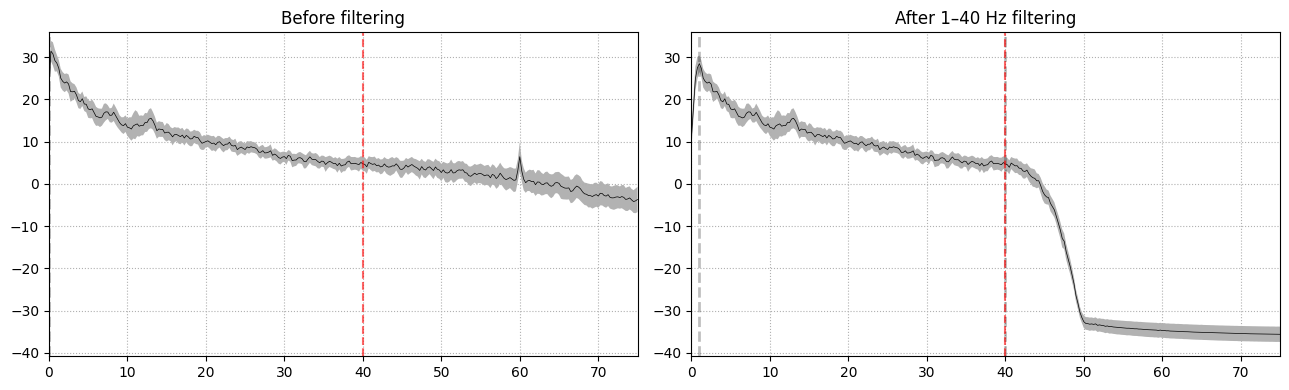

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for recording, title, ax in [
    (raw, "Before filtering", axes[0]),
    (raw_filtered, "After 1–40 Hz filtering", axes[1])
]:
    spectrum = recording.compute_psd(
        method="welch",
        fmin=0,
        fmax=75,
        picks="eeg",
        n_fft=640,
        n_per_seg=640,
        n_overlap=320
    )

    spectrum.plot(
        axes=ax,
        average=True,
        dB=True,
        show=False
    )

    ax.set_title(title)

# Use identical vertical scales for a fair comparison.
limits = [ax.get_ylim() for ax in axes]
shared_limits = (
    min(low for low, high in limits),
    max(high for low, high in limits)
)

for ax in axes:
    ax.set_ylim(shared_limits)
    ax.axvline(40, color="red", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

## 4. Inspect channel quality

Amplitude summaries identify channels to inspect. No channels are declared bad solely because of their rank or amplitude.

In [5]:
import numpy as np
import pandas as pd

# Select EEG channels and convert volts to microvolts.
eeg_picks = mne.pick_types(
    raw_filtered.info,
    meg=False,
    eeg=True,
    exclude=[]
)

eeg_uv = raw_filtered.get_data(picks=eeg_picks) * 1e6
channel_names = [raw_filtered.ch_names[i] for i in eeg_picks]

channel_summary = pd.DataFrame({
    "channel": channel_names,
    "std_uV": np.std(eeg_uv, axis=1),
    "peak_to_peak_uV": np.ptp(eeg_uv, axis=1)
})

print("Already marked bad:", raw_filtered.info["bads"])

print("\n10 channels with highest variability:")
print(
    channel_summary.sort_values("std_uV", ascending=False)
    .head(10).round(2).to_string(index=False)
)

print("\n5 channels with lowest variability:")
print(
    channel_summary.sort_values("std_uV")
    .head(5).round(2).to_string(index=False)
)

Already marked bad: []

10 channels with highest variability:
channel  std_uV  peak_to_peak_uV
   Fp1.   62.77           852.76
   Af7.   58.58           797.57
   Fp2.   57.59           806.70
   Af3.   56.78           762.47
   Fpz.   54.20           706.83
   Af8.   52.50           746.01
   F5..   47.43           518.07
   O2..   47.22           459.37
   Poz.   46.21           420.36
   O1..   45.82           472.89

5 channels with lowest variability:
channel  std_uV  peak_to_peak_uV
   T10.   17.33           154.83
   Ft8.   26.20           252.47
   Tp8.   26.45           226.28
   C6..   30.88           253.94
   T8..   31.64           257.19


## 4.1 Inspect a frontal transient

Compare Fp1 and Fp2 with C3, Cz and C4 around the largest absolute Fp1 fluctuation. These electrodes record mixed scalp potentials, not isolated brain sources.

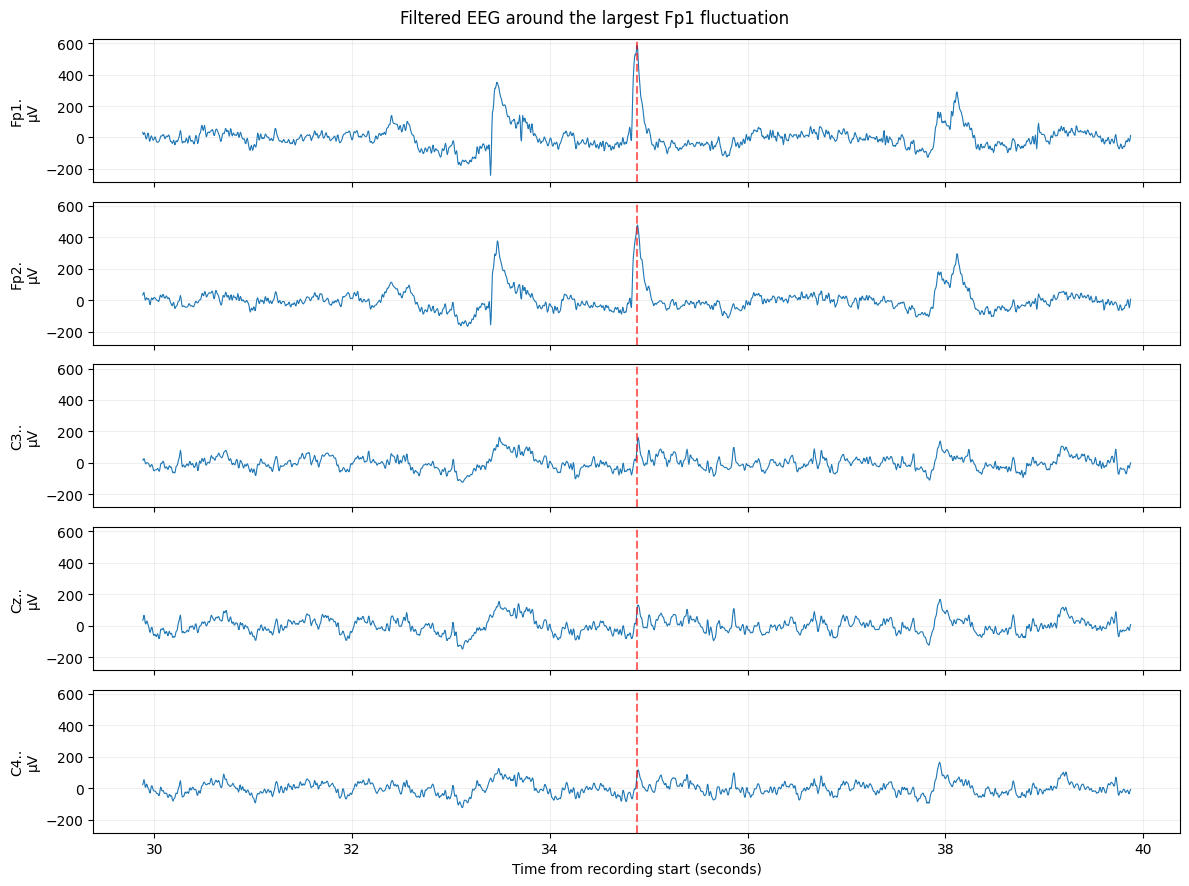

Largest absolute Fp1 fluctuation: 34.88 seconds
Inspection window: 29.88–39.88 seconds


In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Match names such as "Fp1." and "C3.." without renaming the data.
channel_lookup = {
    name.replace(".", "").strip().upper(): name
    for name in raw_filtered.ch_names
}

wanted = ["FP1", "FP2", "C3", "CZ", "C4"]
selected = [channel_lookup[name] for name in wanted]

sfreq = raw_filtered.info["sfreq"]
duration = raw_filtered.n_times / sfreq

# Locate the largest absolute Fp1 fluctuation.
fp1_uv = raw_filtered.get_data(
    picks=[channel_lookup["FP1"]]
)[0] * 1e6

peak_time = np.argmax(np.abs(fp1_uv)) / sfreq

# Keep a ten-second inspection window within the recording.
window_start = max(0.0, min(peak_time - 5.0, duration - 10.0))
start = int(window_start * sfreq)
stop = min(start + int(10 * sfreq), raw_filtered.n_times)

traces_uv = raw_filtered.get_data(
    picks=selected, start=start, stop=stop
) * 1e6

times = np.arange(start, stop) / sfreq

fig, axes = plt.subplots(
    len(selected), 1,
    figsize=(12, 9),
    sharex=True,
    sharey=True
)

for ax, name, trace in zip(axes, selected, traces_uv):
    ax.plot(times, trace, linewidth=0.8)
    ax.axvline(peak_time, color="red", linestyle="--", alpha=0.6)
    ax.set_ylabel(f"{name}\nµV")
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Time from recording start (seconds)")
fig.suptitle("Filtered EEG around the largest Fp1 fluctuation")
plt.tight_layout()
plt.show()

print(f"Largest absolute Fp1 fluctuation: {peak_time:.2f} seconds")
print(f"Inspection window: {times[0]:.2f}–{times[-1]:.2f} seconds")

## 4.2 Relate the transient to task timing

Determine whether the transient peak overlaps a task epoch. Peak timing alone does not define artifact duration or exclude filter-related spread.

In [7]:
import pandas as pd

annotations = pd.DataFrame({
    "onset_s": raw_filtered.annotations.onset,
    "duration_s": raw_filtered.annotations.duration,
    "label": raw_filtered.annotations.description
})

annotations["end_s"] = (
    annotations["onset_s"] + annotations["duration_s"]
)

# Show annotation intervals overlapping the plotted window.
nearby = annotations[
    (annotations["onset_s"] <= times[-1]) &
    (annotations["end_s"] > times[0])
]

print("Annotations overlapping the inspection window:")
print(nearby.round(3).to_string(index=False))

# Identify the annotation interval containing the largest transient.
containing_peak = annotations[
    (annotations["onset_s"] <= peak_time) &
    (annotations["end_s"] > peak_time)
]

print(f"\nAnnotation at the largest transient ({peak_time:.3f} s):")
print(containing_peak.round(3).to_string(index=False))

# Check overlap with candidate epochs from 0 to 3 seconds
# after each left/right imagery onset.
tasks = annotations[annotations["label"].isin(["T1", "T2"])].copy()
tasks["epoch_end_s"] = tasks["onset_s"] + 3.0

overlapping_trials = tasks[
    (tasks["onset_s"] <= peak_time) &
    (tasks["epoch_end_s"] >= peak_time)
]

print("\nCandidate 0–3 s imagery epochs containing this transient:")
if overlapping_trials.empty:
    print("None")
else:
    print(
        overlapping_trials[
            ["label", "onset_s", "epoch_end_s"]
        ].round(3).to_string(index=False)
    )

Annotations overlapping the inspection window:
 onset_s  duration_s label  end_s
    29.1         4.1    T2   33.2
    33.2         4.2    T0   37.4
    37.4         4.1    T2   41.5

Annotation at the largest transient (34.881 s):
 onset_s  duration_s label  end_s
    33.2         4.2    T0   37.4

Candidate 0–3 s imagery epochs containing this transient:
None


## 5. Construct imagery epochs

Use an explicit event mapping and 0-3 seconds after each cue. Both endpoints are included, giving 481 samples at 160 Hz. No baseline subtraction, detrending or amplitude rejection is applied. Existing BAD annotations would be respected. The original reference is retained.

In [8]:
import mne
import numpy as np
import pandas as pd

# Explicit mapping avoids relying on automatically assigned event numbers.
event_codes = {"T1": 1, "T2": 2}

events, _ = mne.events_from_annotations(
    raw_filtered,
    event_id=event_codes
)

epochs_qc = mne.Epochs(
    raw_filtered,
    events,
    event_id={"left": 1, "right": 2},
    tmin=0.0,
    tmax=3.0,
    baseline=None,
    detrend=None,
    picks="eeg",
    preload=True,
    reject=None,
    flat=None,
    reject_by_annotation=True
)

print("Epoch shape:", epochs_qc.get_data().shape)
print("Left trials:", len(epochs_qc["left"]))
print("Right trials:", len(epochs_qc["right"]))
print("Dropped epochs:", [
    (i, reason)
    for i, reason in enumerate(epochs_qc.drop_log)
    if reason
])

# Peak-to-peak amplitude for each channel in each epoch.
epoch_uv = epochs_qc.get_data() * 1e6
ptp_uv = np.ptp(epoch_uv, axis=2)

lookup = {
    name.replace(".", "").strip().upper(): i
    for i, name in enumerate(epochs_qc.ch_names)
}

trial_qc = pd.DataFrame({
    "trial": np.arange(1, len(epochs_qc) + 1),
    "onset_s": (
        epochs_qc.events[:, 0] - raw_filtered.first_samp
    ) / raw_filtered.info["sfreq"],
    "label": [
        "left" if code == 1 else "right"
        for code in epochs_qc.events[:, 2]
    ]
})

for channel in ["FP1", "FP2", "C3", "CZ", "C4"]:
    trial_qc[f"{channel}_ptp_uV"] = ptp_uv[:, lookup[channel]]

print("\nPeak-to-peak amplitude by trial:")
print(trial_qc.round(2).to_string(index=False))

Used Annotations descriptions: ['T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 481 original time points ...
0 bad epochs dropped
Epoch shape: (15, 64, 481)
Left trials: 8
Right trials: 7
Dropped epochs: []

Peak-to-peak amplitude by trial:
 trial  onset_s label  FP1_ptp_uV  FP2_ptp_uV  C3_ptp_uV  CZ_ptp_uV  C4_ptp_uV
     1      4.2 right      557.19      423.25     228.40     214.55     191.45
     2     12.5  left      173.86      139.92     208.34     269.73     225.35
     3     20.8  left      409.80      314.77     313.88     334.44     266.16
     4     29.1 right      207.85      162.73     190.44     194.35     183.59
     5     37.4 right      416.09      401.66     247.31     289.77     260.60
     6     45.7  left      286.80      205.40     236.54     292.98     214.26
     7     54.0 right      612.75      572.41     217.60     242.60     220.25
     8   

## 5.1 Review all imagery trials

Inspect all 15 trials on common amplitude scales. Frontal transients were observed, including in task epochs. We retain all trials for this exploratory baseline and do not describe them as artifact-free. Selecting central channels does not guarantee removal of ocular contamination.

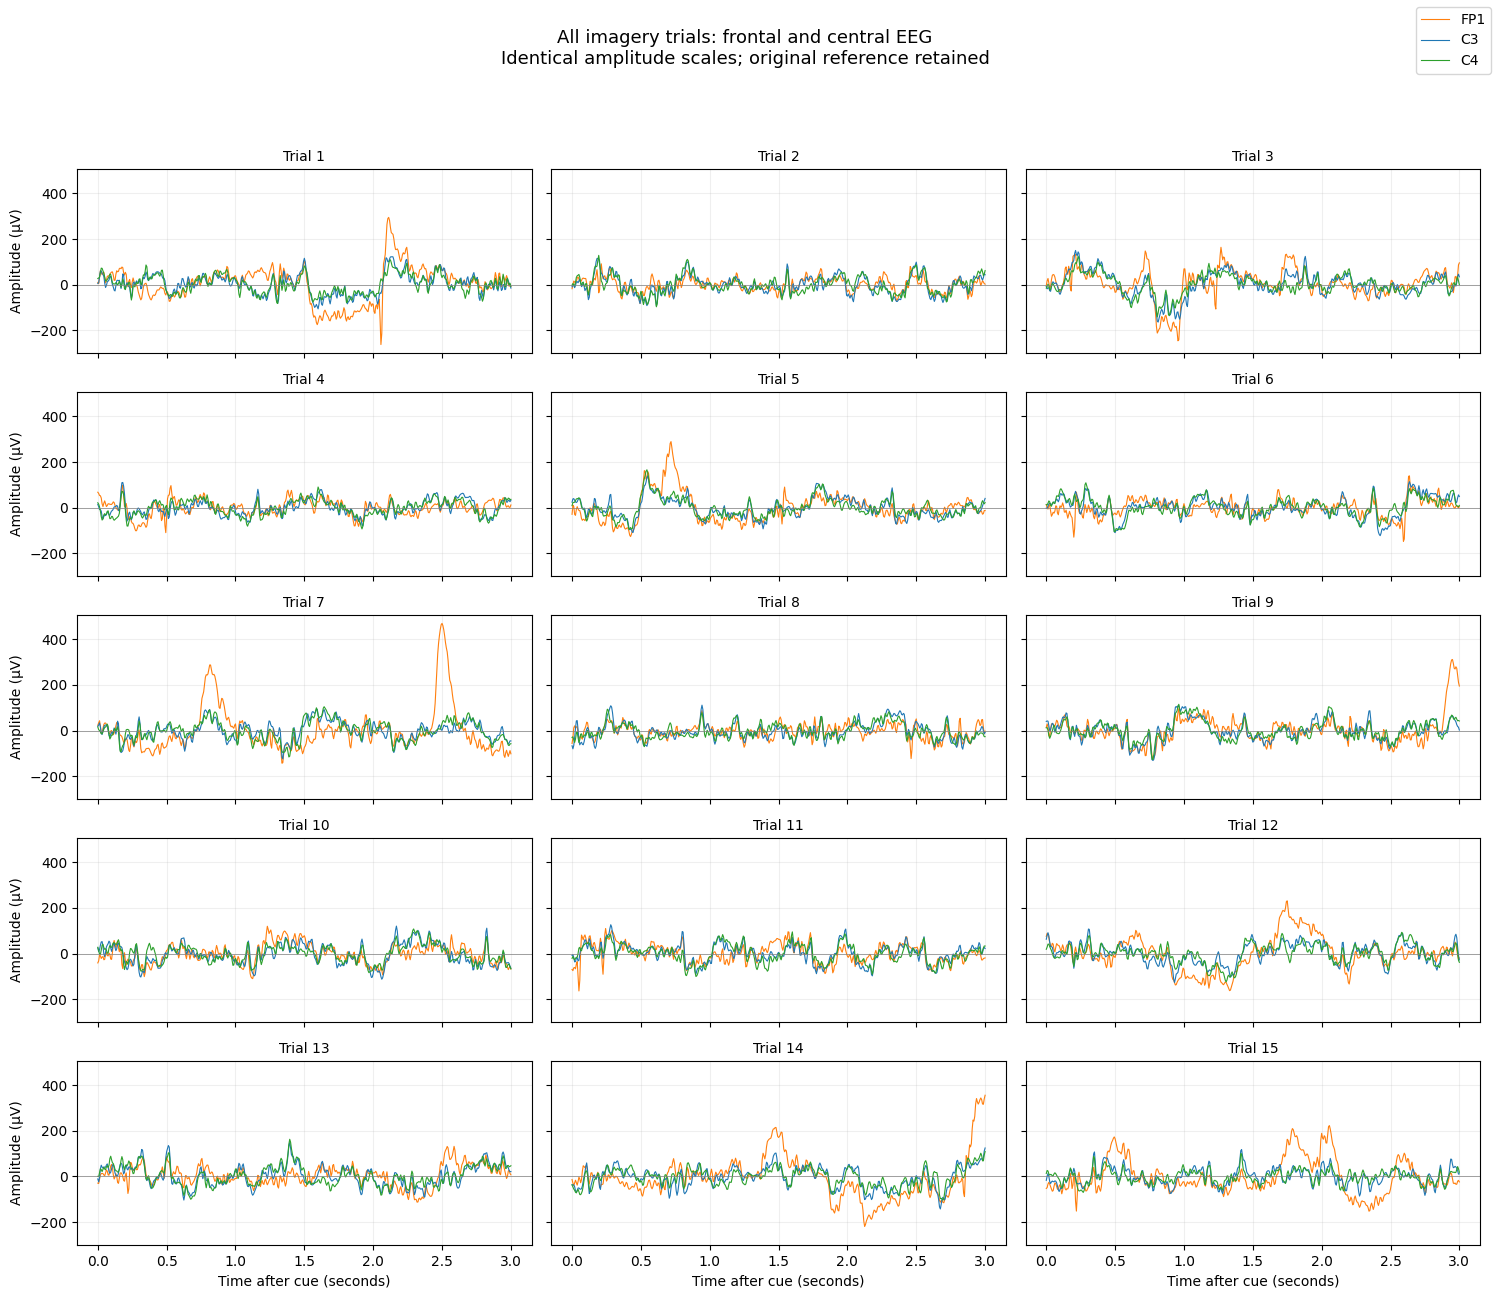

In [10]:
import matplotlib.pyplot as plt

channels_to_plot = ["FP1", "C3", "C4"]
colors = ["tab:orange", "tab:blue", "tab:green"]

fig, axes = plt.subplots(
    5, 3,
    figsize=(15, 13),
    sharex=True,
    sharey=True
)

for i, ax in enumerate(axes.flat):
    for channel, color in zip(channels_to_plot, colors):
        ax.plot(
            epochs_qc.times,
            epoch_uv[i, lookup[channel], :],
            color=color,
            linewidth=0.8,
            label=channel
        )

    ax.axhline(0, color="grey", linewidth=0.5)
    ax.set_title(f"Trial {i + 1}", fontsize=10)
    ax.grid(alpha=0.2)

for ax in axes[-1, :]:
    ax.set_xlabel("Time after cue (seconds)")

for ax in axes[:, 0]:
    ax.set_ylabel("Amplitude (µV)")

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right")

fig.suptitle(
    "All imagery trials: frontal and central EEG\n"
    "Identical amplitude scales; original reference retained",
    fontsize=13
)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

## 6. Extract six features

C3, Cz and C4 sample the central scalp overlying sensorimotor regions. For each trial, Welch spectra use two-second windows with one-second overlap. Integrate 8-13 Hz (mu) and 13-30 Hz (beta), then express power in dB relative to 1 microvolt squared. The shared 13 Hz endpoint is an integration boundary. These are absolute band-power features, not baseline-normalized desynchronization measurements. Bands and electrodes are fixed before model evaluation.

In [11]:
import numpy as np
import pandas as pd
from scipy.integrate import trapezoid

# Select central channels, preserving all trials.
name_lookup = {
    name.replace(".", "").strip().upper(): name
    for name in epochs_qc.ch_names
}
central_names = [name_lookup[ch] for ch in ["C3", "CZ", "C4"]]

epochs_features = epochs_qc.copy().pick(central_names)

# Two-second windows with one-second overlap.
spectrum = epochs_features.compute_psd(
    method="welch",
    fmin=8.0,
    fmax=30.0,
    n_fft=320,
    n_per_seg=320,
    n_overlap=160,
    average="mean"
)

psd, frequencies = spectrum.get_data(return_freqs=True)

# MNE EEG PSD is in V²/Hz; convert to µV²/Hz.
psd_uv2 = psd * 1e12

bands = {
    "mu": (8.0, 13.0),
    "beta": (13.0, 30.0)
}

features = {}

for channel_index, channel_name in enumerate(spectrum.ch_names):
    clean_name = channel_name.replace(".", "").strip()

    for band_name, (low, high) in bands.items():
        mask = (frequencies >= low) & (frequencies <= high)

        power_uv2 = trapezoid(
            psd_uv2[:, channel_index, mask],
            x=frequencies[mask],
            axis=-1
        )

        if not np.all(np.isfinite(power_uv2) & (power_uv2 > 0)):
            raise ValueError("Non-positive or non-finite band power found.")

        # Decibels relative to 1 µV².
        features[f"{clean_name}_{band_name}_dB"] = (
            10 * np.log10(power_uv2)
        )

X = pd.DataFrame(features)

# Encode left as 0, right as 1.
y = (epochs_features.events[:, 2] == 2).astype(int)

print("Feature matrix shape:", X.shape)
print("All features finite:", np.isfinite(X.to_numpy()).all())
print("Class counts: left =", (y == 0).sum(),
      ", right =", (y == 1).sum())

print("\nFirst five trials:")
print(X.head().round(3).to_string(index=False))

Effective window size : 2.000 (s)
Feature matrix shape: (15, 6)
All features finite: True
Class counts: left = 8 , right = 7

First five trials:
 C3_mu_dB  C3_beta_dB  Cz_mu_dB  Cz_beta_dB  C4_mu_dB  C4_beta_dB
   21.987      21.978    21.352      22.216    19.770      21.993
   18.924      22.025    19.174      21.392    18.161      20.384
   22.482      22.688    21.614      22.754    19.928      21.838
   20.577      20.454    20.783      20.735    19.688      20.156
   17.933      21.003    18.670      21.310    18.542      19.978


## 7. Exploratory validation within R04

A StandardScaler and logistic regression (C=1.0) are fitted inside each fold. Three contiguous blocks of five trials are held out in turn. This is not forward-only validation: a training set may contain later trials. All data are from the same run, so scores are exploratory and temporal dependence remains possible. The dummy predicts the most frequent training class. No model or hyperparameter search is performed.

In [13]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import KFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix
)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        C=1.0,
        solver="lbfgs",
        max_iter=2000
    )
)

dummy = DummyClassifier(strategy="most_frequent")

# Keep trials in their existing chronological order.
cv = KFold(n_splits=3, shuffle=False)

oof_pred = np.full(len(y), -1, dtype=int)
dummy_pred = np.full(len(y), -1, dtype=int)
fold_results = []

for fold, (train_idx, test_idx) in enumerate(cv.split(X), start=1):
    assert len(np.unique(y[train_idx])) == 2
    assert len(np.unique(y[test_idx])) == 2

    fitted_model = clone(model)
    fitted_dummy = clone(dummy)

    fitted_model.fit(X.iloc[train_idx], y[train_idx])
    fitted_dummy.fit(X.iloc[train_idx], y[train_idx])

    predictions = fitted_model.predict(X.iloc[test_idx])
    baseline_predictions = fitted_dummy.predict(X.iloc[test_idx])

    oof_pred[test_idx] = predictions
    dummy_pred[test_idx] = baseline_predictions

    fold_results.append({
        "fold": fold,
        "test_trials": f"{test_idx[0] + 1}-{test_idx[-1] + 1}",
        "accuracy": accuracy_score(y[test_idx], predictions),
        "balanced_accuracy": balanced_accuracy_score(
            y[test_idx], predictions
        ),
        "dummy_balanced_accuracy": balanced_accuracy_score(
            y[test_idx], baseline_predictions
        )
    })

assert np.all(oof_pred >= 0)
assert np.all(dummy_pred >= 0)

print("Scores by fold (0–1 scale):")
print(pd.DataFrame(fold_results).round(3).to_string(index=False))

print("\nPooled held-out predictions:")
for name, predictions in [
    ("Logistic regression", oof_pred),
    ("Dummy classifier", dummy_pred)
]:
    print(
        f"{name}: "
        f"accuracy = {accuracy_score(y, predictions):.3f}, "
        f"balanced accuracy = "
        f"{balanced_accuracy_score(y, predictions):.3f}"
    )

print("\nLogistic-regression confusion matrix:")
print(pd.DataFrame(
    confusion_matrix(y, oof_pred, labels=[0, 1]),
    index=["Actual left", "Actual right"],
    columns=["Predicted left", "Predicted right"]
))

Scores by fold (0–1 scale):
 fold test_trials  accuracy  balanced_accuracy  dummy_balanced_accuracy
    1         1-5       0.4              0.500                      0.5
    2        6-10       0.6              0.583                      0.5
    3       11-15       1.0              1.000                      0.5

Pooled held-out predictions:
Logistic regression: accuracy = 0.667, balanced accuracy = 0.652
Dummy classifier: accuracy = 0.533, balanced accuracy = 0.500

Logistic-regression confusion matrix:
              Predicted left  Predicted right
Actual left                7                1
Actual right               4                3


## 8. Load separate test runs

R08 and R12 contain the same left/right imagery task. Their class counts differ: R08 has 8 left and 7 right; R12 has 7 left and 8 right. Verify structure before processing.

In [14]:
from pathlib import Path
from urllib.request import urlretrieve
from collections import Counter
import mne

additional_raws = {}

for run in [8, 12]:
    filename = f"S001R{run:02d}.edf"
    file_path = Path("/kaggle/working") / filename
    url = (
        "https://physionet.org/files/eegmmidb/1.0.0/"
        f"S001/{filename}"
    )

    if not file_path.exists():
        urlretrieve(url, str(file_path))

    recording = mne.io.read_raw_edf(
        str(file_path),
        preload=True
    )

    additional_raws[run] = recording
    counts = Counter(recording.annotations.description)

    print("\nFile:", filename)
    print("Channels:", len(recording.ch_names))
    print("Sampling frequency:", recording.info["sfreq"], "Hz")
    print(
        "Duration:",
        round(recording.n_times / recording.info["sfreq"], 2),
        "seconds"
    )
    print("Annotation counts:", dict(counts))
    print(
        "Channel names/order match R04:",
        recording.ch_names == raw.ch_names
    )

Extracting EDF parameters from /kaggle/working/S001R08.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 19999  =      0.000 ...   124.994 secs...

File: S001R08.edf
Channels: 64
Sampling frequency: 160.0 Hz
Duration: 125.0 seconds
Annotation counts: {'T0': 15, 'T1': 8, 'T2': 7}
Channel names/order match R04: True
Extracting EDF parameters from /kaggle/working/S001R12.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 19999  =      0.000 ...   124.994 secs...

File: S001R12.edf
Channels: 64
Sampling frequency: 160.0 Hz
Duration: 125.0 seconds
Annotation counts: {'T0': 15, 'T2': 8, 'T1': 7}
Channel names/order match R04: True


## 8.1 Apply the fixed feature pipeline

Filter each test run separately using the same settings as R04. Preserve the reference, epoch window, channels and frequency bands. No scaling parameters or model coefficients are learned here. Artifact quality in these runs has not been comprehensively assessed.

In [15]:
import mne
import numpy as np
import pandas as pd
from scipy.integrate import trapezoid

def extract_run_features(recording):
    # Apply exactly the same filter as R04.
    filtered = recording.copy().load_data()
    filtered.filter(
        l_freq=1.0,
        h_freq=40.0,
        picks="eeg",
        method="fir",
        fir_design="firwin",
        phase="zero"
    )

    events, _ = mne.events_from_annotations(
        filtered,
        event_id={"T1": 1, "T2": 2}
    )

    epochs = mne.Epochs(
        filtered,
        events,
        event_id={"left": 1, "right": 2},
        tmin=0.0,
        tmax=3.0,
        baseline=None,
        detrend=None,
        picks="eeg",
        preload=True,
        reject=None,
        flat=None,
        reject_by_annotation=True
    )

    name_lookup = {
        name.replace(".", "").strip().upper(): name
        for name in epochs.ch_names
    }

    central = epochs.copy().pick([
        name_lookup[ch] for ch in ["C3", "CZ", "C4"]
    ])

    spectrum = central.compute_psd(
        method="welch",
        fmin=8.0,
        fmax=30.0,
        n_fft=320,
        n_per_seg=320,
        n_overlap=160,
        average="mean"
    )

    psd, frequencies = spectrum.get_data(return_freqs=True)
    psd_uv2 = psd * 1e12

    features = {}

    for channel_index, channel_name in enumerate(spectrum.ch_names):
        clean_name = channel_name.replace(".", "").strip()

        for band_name, (low, high) in {
            "mu": (8.0, 13.0),
            "beta": (13.0, 30.0)
        }.items():
            mask = (frequencies >= low) & (frequencies <= high)

            power = trapezoid(
                psd_uv2[:, channel_index, mask],
                x=frequencies[mask],
                axis=-1
            )

            if not np.all(np.isfinite(power) & (power > 0)):
                raise ValueError("Invalid band power detected.")

            features[f"{clean_name}_{band_name}_dB"] = (
                10 * np.log10(power)
            )

    features_df = pd.DataFrame(features)
    labels = (epochs.events[:, 2] == 2).astype(int)

    return features_df, labels, epochs


# Keep the original R04 feature matrix X and labels y unchanged.
test_runs = {}

for run in [8, 12]:
    run_X, run_y, run_epochs = extract_run_features(
        additional_raws[run]
    )

    # Check feature names and order against the training data.
    assert list(run_X.columns) == list(X.columns), \
        "Feature columns do not match R04."

    test_runs[run] = {
        "X": run_X,
        "y": run_y,
        "epochs": run_epochs
    }

    print(f"\nRUN R{run:02d}")
    print("Epoch shape:", run_epochs.get_data().shape)
    print("Feature shape:", run_X.shape)
    print("All features finite:", np.isfinite(run_X.to_numpy()).all())
    print("Left:", int((run_y == 0).sum()))
    print("Right:", int((run_y == 1).sum()))
    print("Dropped epochs:", [
        (i, reason)
        for i, reason in enumerate(run_epochs.drop_log)
        if reason
    ])

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 529 samples (3.306 s)

Used Annotations descriptions: ['T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 481 original time points ...
0 bad epochs dropped
Effective window size : 2.000 (s)

RUN R08
Epoch shape: (15, 64, 481)
Feature shape: (15, 6)
All features finite: True
Left: 8
Right: 7
Dropped epochs: []
Filtering raw data in 1 contiguous s

## 9. Evaluate the R04-trained model

Fit the scaler and classifier on all 15 R04 trials only. Predict R08 and R12 without refitting on test data. Report both runs, confusion matrices and pooled predictions. Do not tune the model against these results; future revisions need fresh evaluation data.

In [16]:
import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix
)

# Same settings as the exploratory model.
run_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        C=1.0,
        solver="lbfgs",
        max_iter=2000
    )
)

run_dummy = DummyClassifier(strategy="most_frequent")

# Fit ONLY on R04.
run_model.fit(X, y)
run_dummy.fit(X, y)

results = []
heldout_predictions = {}

for run in [8, 12]:
    test_X = test_runs[run]["X"]
    test_y = test_runs[run]["y"]

    assert list(test_X.columns) == list(X.columns)

    # No fitting or scaling updates on the test runs.
    predictions = run_model.predict(test_X)
    baseline_predictions = run_dummy.predict(test_X)

    heldout_predictions[run] = {
        "true": test_y.copy(),
        "predicted": predictions.copy(),
        "dummy": baseline_predictions.copy()
    }

    results.append({
        "run": f"R{run:02d}",
        "correct": int((predictions == test_y).sum()),
        "trials": len(test_y),
        "accuracy": accuracy_score(test_y, predictions),
        "balanced_accuracy": balanced_accuracy_score(
            test_y, predictions
        ),
        "dummy_accuracy": accuracy_score(
            test_y, baseline_predictions
        ),
        "dummy_balanced_accuracy": balanced_accuracy_score(
            test_y, baseline_predictions
        )
    })

    print(f"\nR{run:02d} confusion matrix:")
    print(pd.DataFrame(
        confusion_matrix(test_y, predictions, labels=[0, 1]),
        index=["Actual left", "Actual right"],
        columns=["Predicted left", "Predicted right"]
    ))

print("\nSeparate-run results:")
print(pd.DataFrame(results).round(3).to_string(index=False))

# Pool the predictions from both test runs.
pooled_true = np.concatenate([
    heldout_predictions[run]["true"] for run in [8, 12]
])
pooled_pred = np.concatenate([
    heldout_predictions[run]["predicted"] for run in [8, 12]
])
pooled_dummy = np.concatenate([
    heldout_predictions[run]["dummy"] for run in [8, 12]
])

print("\nCombined R08 + R12 results:")
for name, predictions in [
    ("Logistic regression", pooled_pred),
    ("Dummy classifier", pooled_dummy)
]:
    print(
        f"{name}: "
        f"correct = {(predictions == pooled_true).sum()}/"
        f"{len(pooled_true)}, "
        f"accuracy = {accuracy_score(pooled_true, predictions):.3f}, "
        f"balanced accuracy = "
        f"{balanced_accuracy_score(pooled_true, predictions):.3f}"
    )


R08 confusion matrix:
              Predicted left  Predicted right
Actual left                7                1
Actual right               5                2

R12 confusion matrix:
              Predicted left  Predicted right
Actual left                6                1
Actual right               4                4

Separate-run results:
run  correct  trials  accuracy  balanced_accuracy  dummy_accuracy  dummy_balanced_accuracy
R08        9      15     0.600              0.580           0.533                      0.5
R12       10      15     0.667              0.679           0.467                      0.5

Combined R08 + R12 results:
Logistic regression: correct = 19/30, accuracy = 0.633, balanced accuracy = 0.633
Dummy classifier: correct = 15/30, accuracy = 0.500, balanced accuracy = 0.500


## 10. Results and interpretation

**Results reproduced in the successful Kaggle Version 2 run and checked on 12 October 2026.**

| Evaluation | Correct | Accuracy | Balanced accuracy |
|---|---:|---:|---:|
| R04 contiguous-block cross-validation | 10/15 | 66.7% | 65.2% |
| R04-trained model tested on R08 | 9/15 | 60.0% | 58.0% |
| R04-trained model tested on R12 | 10/15 | 66.7% | 67.9% |
| R08 + R12 combined | 19/30 | 63.3% | 63.3% |
| Combined dummy baseline | 15/30 | 50.0% | 50.0% |

The test runs together contain 15 trials of each class. The combined confusion matrix is:

| | Predicted left | Predicted right |
|---|---:|---:|
| Actual left | 13 | 2 |
| Actual right | 9 | 6 |

Left recall was 86.7% and right recall 40.0%. The model predicted left on 22/30 trials and made four more correct predictions than the dummy. The earlier 66.7% R04 result is a different evaluation and should not be substituted for the separate-run score.

The observed results suggest modest predictive performance in these recordings, with unequal class recall. They do not establish statistically reliable above-chance decoding or demonstrate that predictions arise solely from motor-related neural activity.

## 11. Limitations

- One participant, 15 training trials and 30 test trials; no claim about new people or independent sessions.
- Prominent frontal transients, plausibly eye-related, were observed. Their source was not confirmed, and no ICA, EOG-based correction, or amplitude rejection was applied.
- Frontal amplitudes tended to differ by class in R04. Central electrodes can also contain artifacts, so a task-associated non-neural confound remains possible.
- Test-run structural checks passed, but test-run artifact inspection was limited.
- Original reference retained; no systematic comparison of references or channel-quality assessment across all runs.
- Zero-phase filtering is offline and may spread transients in time. Initial within-run validation does not eliminate temporal dependence.
- Absolute mu/beta power is not proof of contralateral cortical activation or event-related desynchronization; no rest-normalized analysis was performed.
- No significance test or independent uncertainty analysis was completed. Do not call the result significant.
- Test scores have now been observed. Future tuning on these runs would make them development data and require fresh test data.

## 12. Learning outcomes and future work

This project demonstrates EDF loading, annotation interpretation, frequency filtering, quality inspection, epoching, spectral feature extraction, leakage-aware scaling, simple classification, and separate-run evaluation. Its scientific value includes recognising limitations and reporting a modest result honestly.

A future extension could predefine artifact handling, collect additional participants and evaluate with participant-level grouping. These extensions have not been completed and are not required to finish this first version.

## 13. Sources

- PhysioNet EEG Motor Movement/Imagery Dataset, version 1.0.0: https://physionet.org/content/eegmmidb/1.0.0/ ; DOI: https://doi.org/10.13026/C28G6P . Follow the dataset's attribution and licence terms when sharing data.
- MNE filtering tutorial: https://mne.tools/stable/auto_tutorials/preprocessing/30_filtering_resampling.html
- MNE spectral data tutorial: https://mne.tools/stable/auto_tutorials/time-freq/10_spectrum_class.html
- scikit-learn leakage guidance: https://scikit-learn.org/stable/common_pitfalls.html
- Original working notebook: https://www.kaggle.com/code/jamiuhassan/decoding-left-and-righthand-motor-imagery-from-eeg
